# PRCP-1000-PortugeseBank

# Project ID: PRCP-1000

# Domain: Finance/Banking

# Problem Statement

The objective of this project is to analyze customer data from a Portuguese bank's direct phone-marketing campaigns and develop a predictive machine-learning model to identify customers who are likely to subscribe to a term deposit.

In [1]:
# ------------------------
# Import Libraries
# ------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [2]:
# ------------------------
# Load Dataset
# ------------------------

df=pd.read_csv("bank-additional-full.csv",sep=";")
print("Dataset Loaded Successfully")
print(df.shape)

Dataset Loaded Successfully
(41188, 21)


In [3]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

# Domain Analysis

Client Demographics: age, job, marital, education

Financial/Credit Status: default (credit in default?), housing (housing loan?), loan (personal loan?)

Last Contact Details: contact (communication type), month, day_of_week, duration (in seconds)

Campaign Attributes: campaign (contacts during current campaign), pdays (days since last contact from previous campaign), previous (contacts before current campaign), poutcome (previous campaign outcome)

Macroeconomic Indicators: emp.var.rate (employment variation rate), cons.price.idx (consumer price index), cons.conf.idx (consumer confidence index), euribor3m (Euribor 3 month rate), nr.employed (number of employees)

Target Variable: y (subscribed a term deposit: yes/no)

In [4]:
pd.set_option("display.max_columns", None)
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [6]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(12)

In [8]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

numeric_cols

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='str')

In [9]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


# Exploratory Data Analysis

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


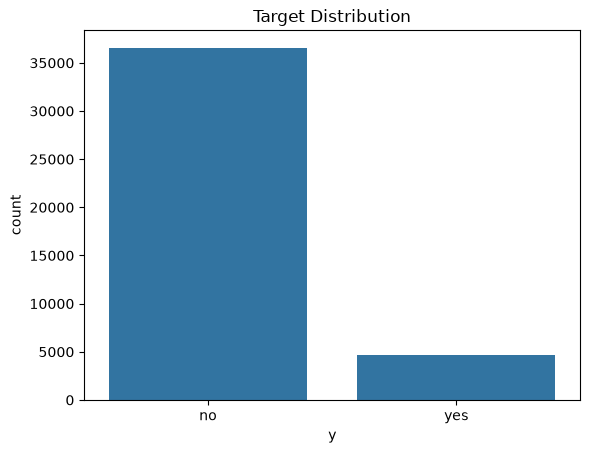

In [10]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='y')
plt.title('Target Distribution')
plt.show()

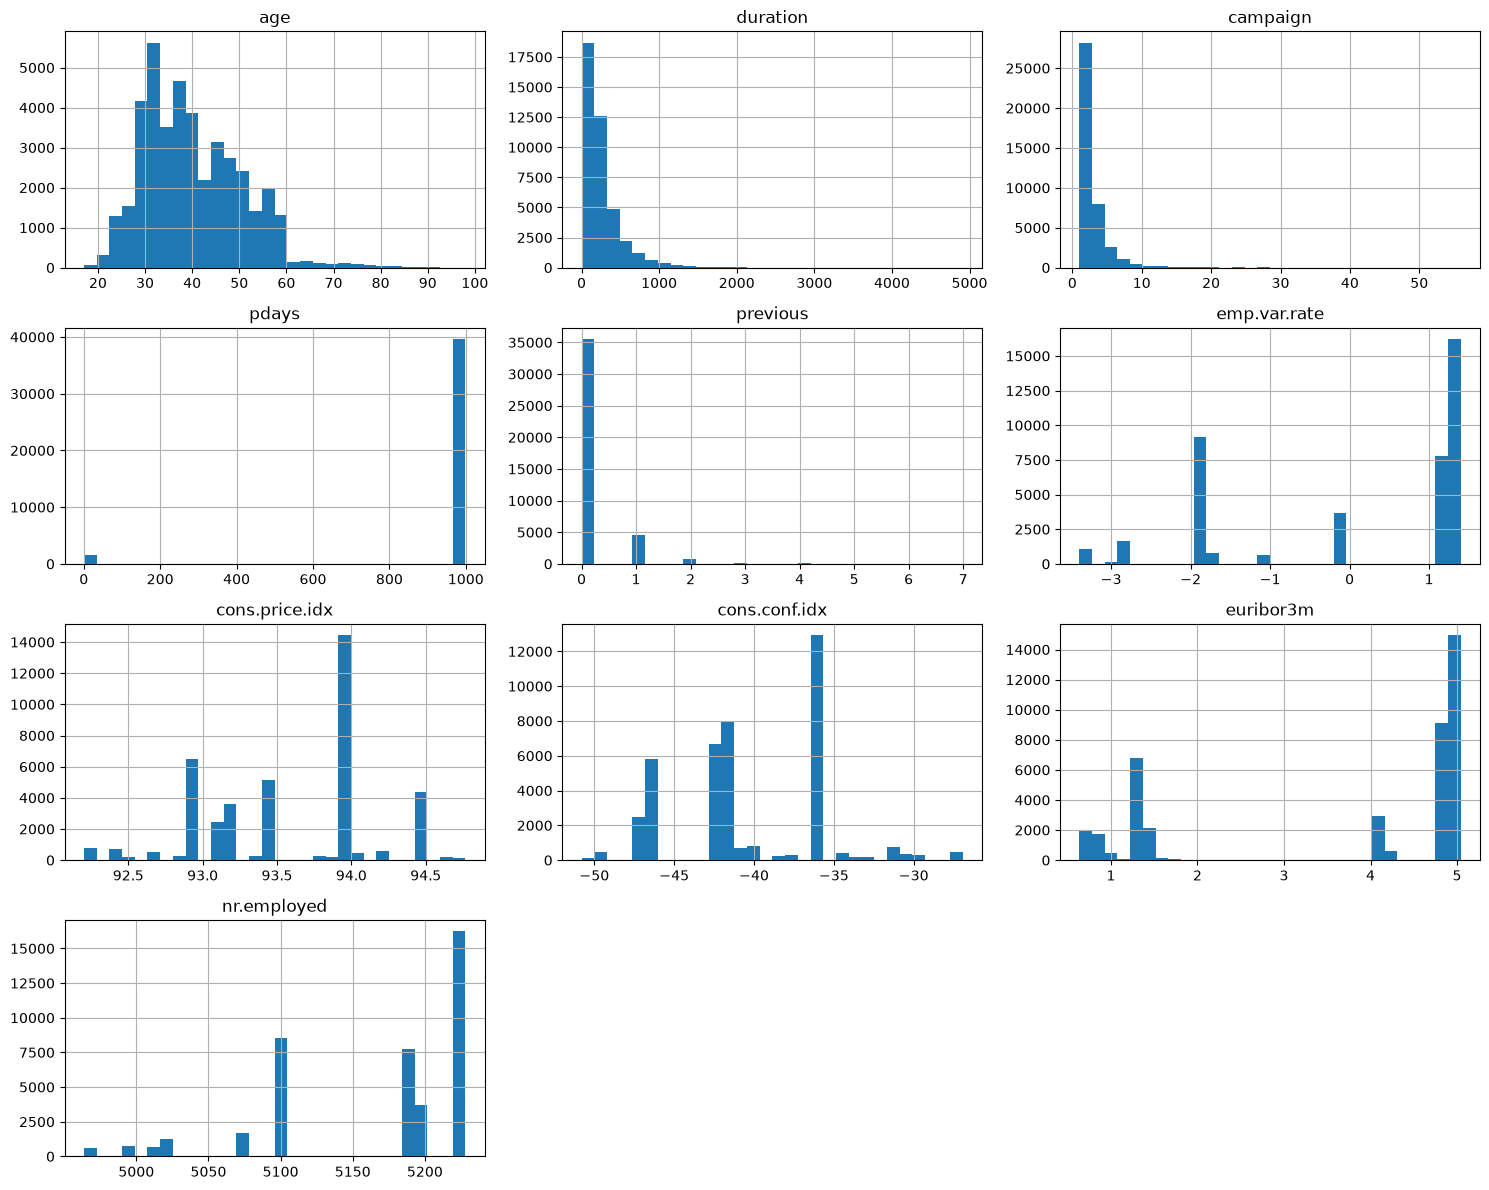

In [11]:
df[numeric_cols].hist(
    figsize=(15, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [12]:
categorical_cols = ['job', 'marital', 'education', 'default',
                    'housing', 'loan', 'contact', 'month',
                    'day_of_week', 'poutcome']

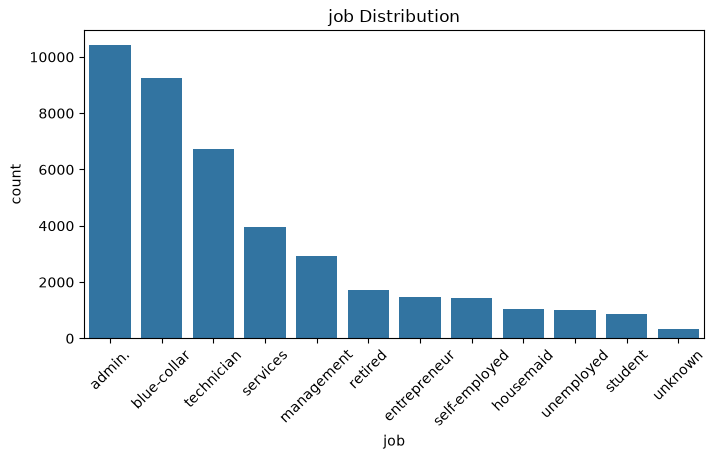

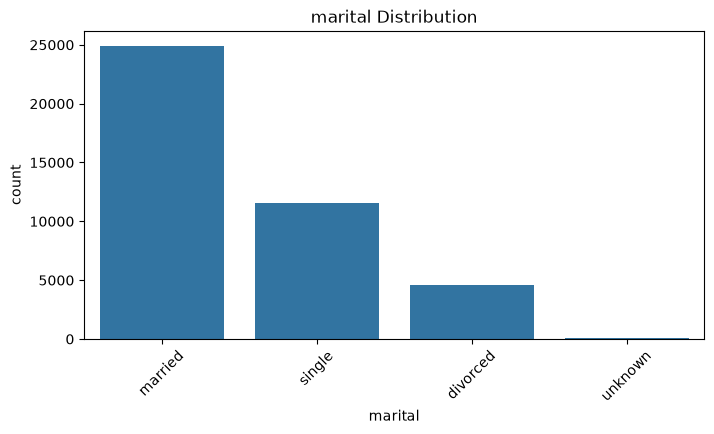

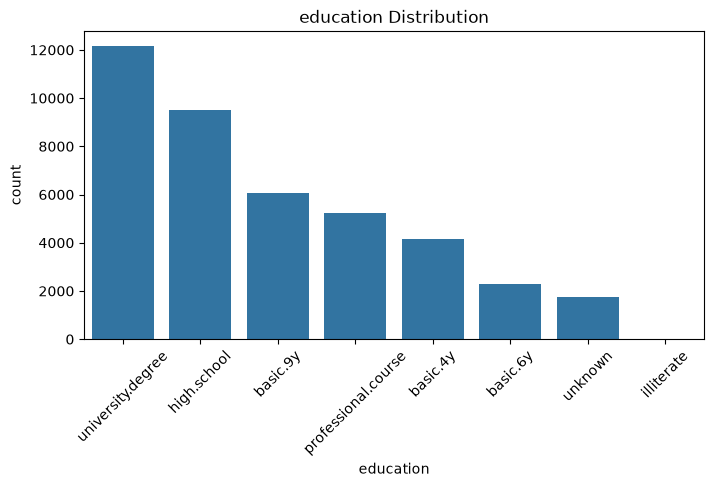

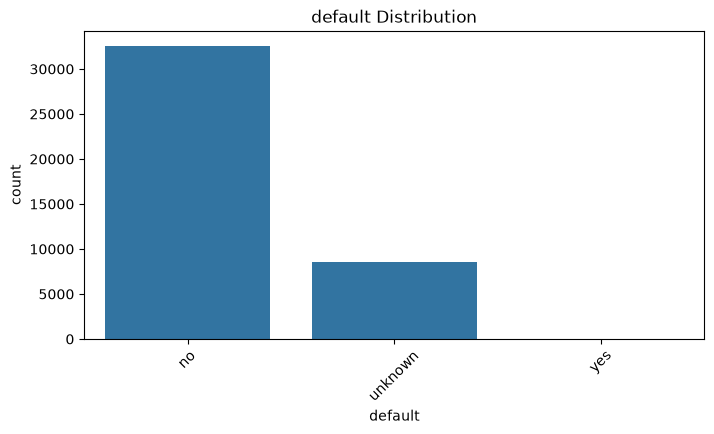

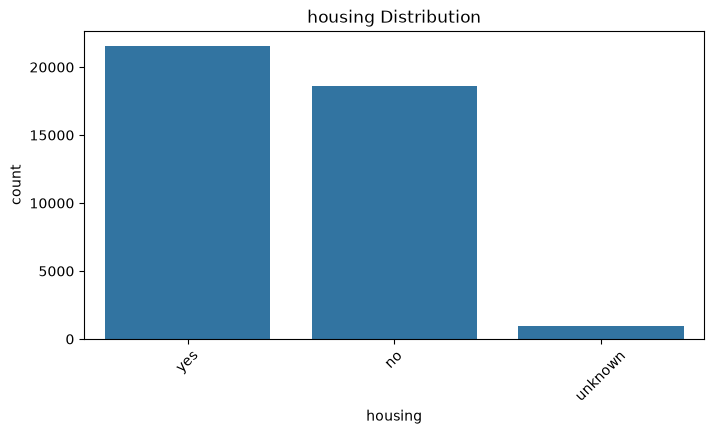

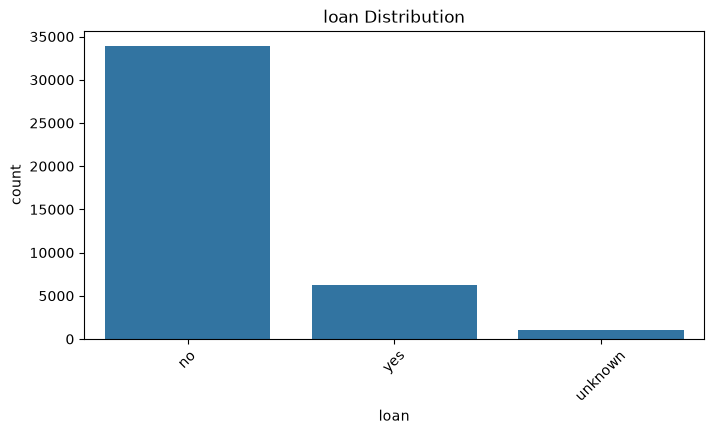

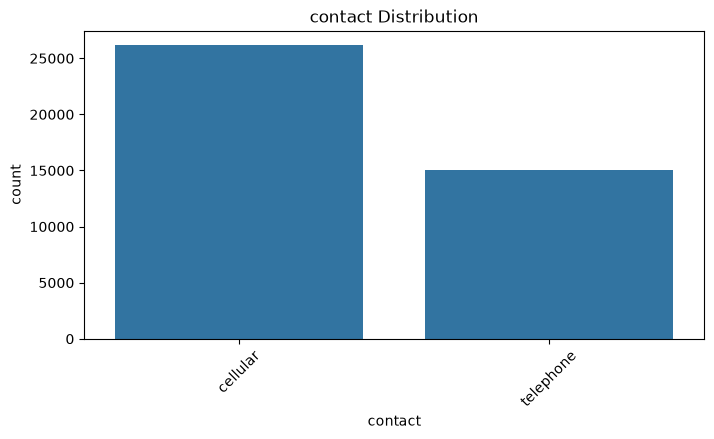

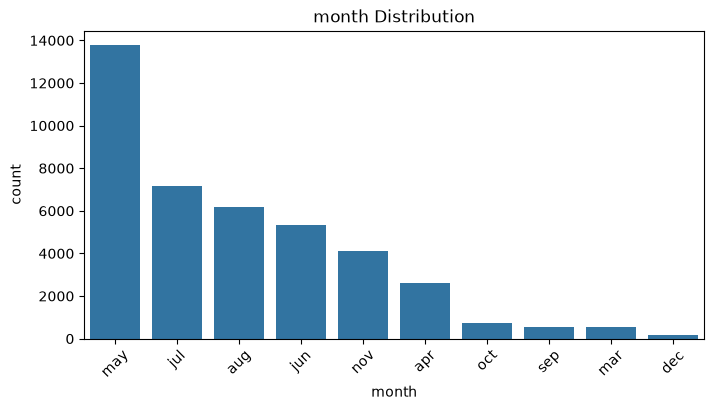

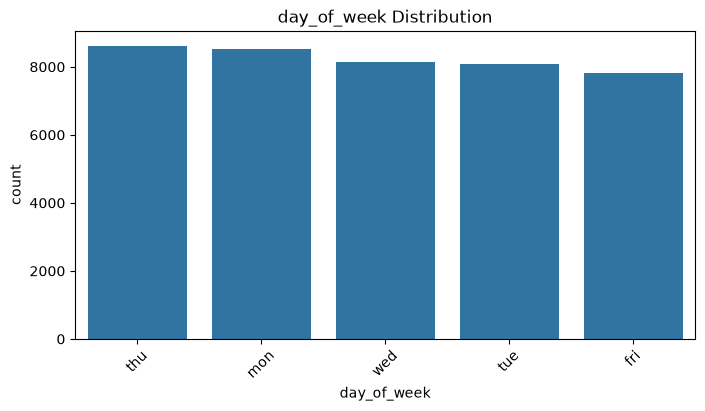

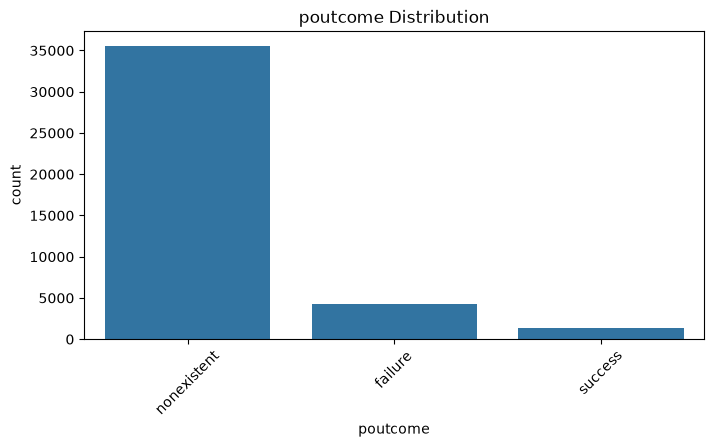

In [13]:
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'{col} Distribution')
    plt.xticks(rotation=45)
    plt.show()

In [14]:
for col in ['job', 'education', 'marital', 'housing',
            'loan', 'contact', 'poutcome']:
    
    print(f"\n{col}")
    print(pd.crosstab(df[col], df['y'], normalize='index') * 100)


job
y                     no        yes
job                                
admin.         87.027442  12.972558
blue-collar    93.105684   6.894316
entrepreneur   91.483516   8.516484
housemaid      90.000000  10.000000
management     88.782490  11.217510
retired        74.767442  25.232558
self-employed  89.514426  10.485574
services       91.861930   8.138070
student        68.571429  31.428571
technician     89.173958  10.826042
unemployed     85.798817  14.201183
unknown        88.787879  11.212121

education
y                           no        yes
education                                
basic.4y             89.750958  10.249042
basic.6y             91.797557   8.202443
basic.9y             92.175352   7.824648
high.school          89.164477  10.835523
illiterate           77.777778  22.222222
professional.course  88.651535  11.348465
university.degree    86.275477  13.724523
unknown              85.499711  14.500289

marital
y                no        yes
marital             

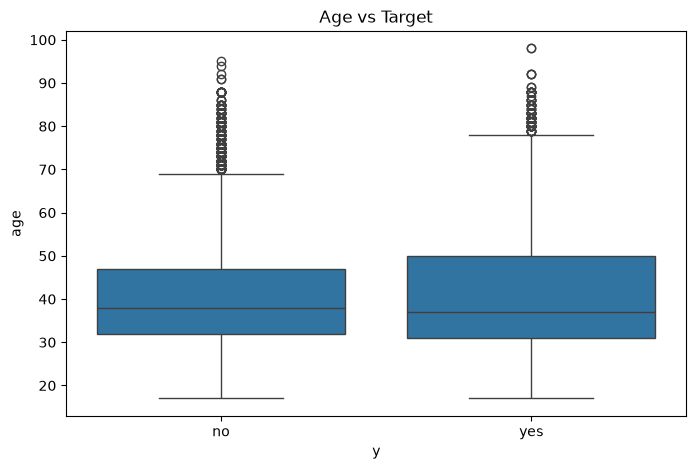

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='y', y='age')
plt.title('Age vs Target')
plt.show()

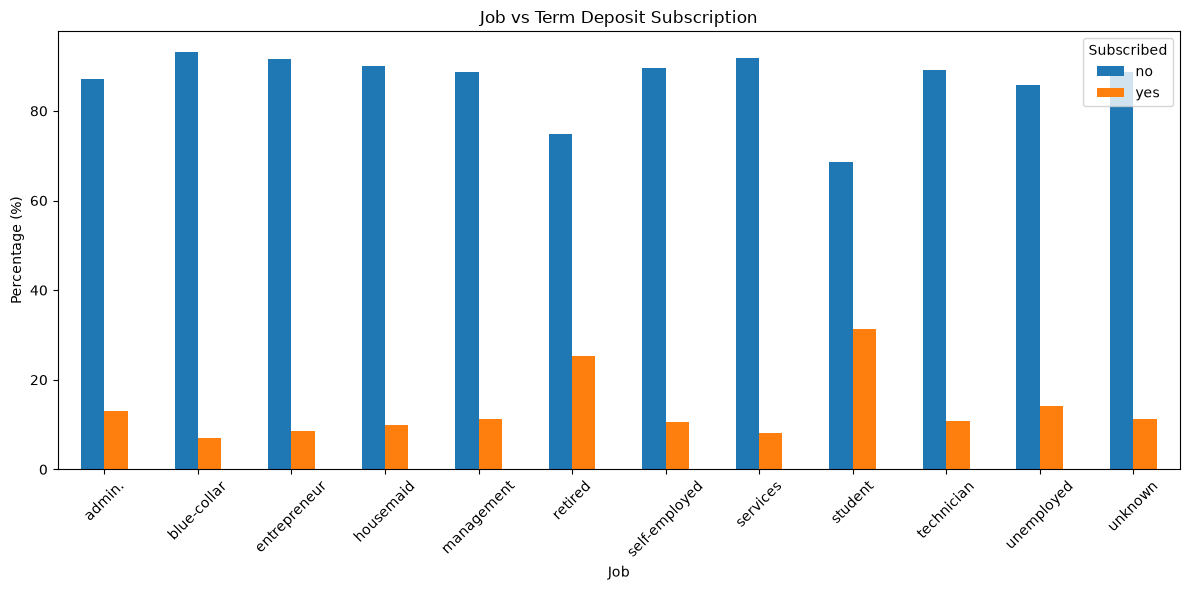

In [16]:
job_target = pd.crosstab(df['job'], df['y'], normalize='index') * 100

job_target.plot(kind='bar', figsize=(12, 6))
plt.title('Job vs Term Deposit Subscription')
plt.xlabel('Job')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

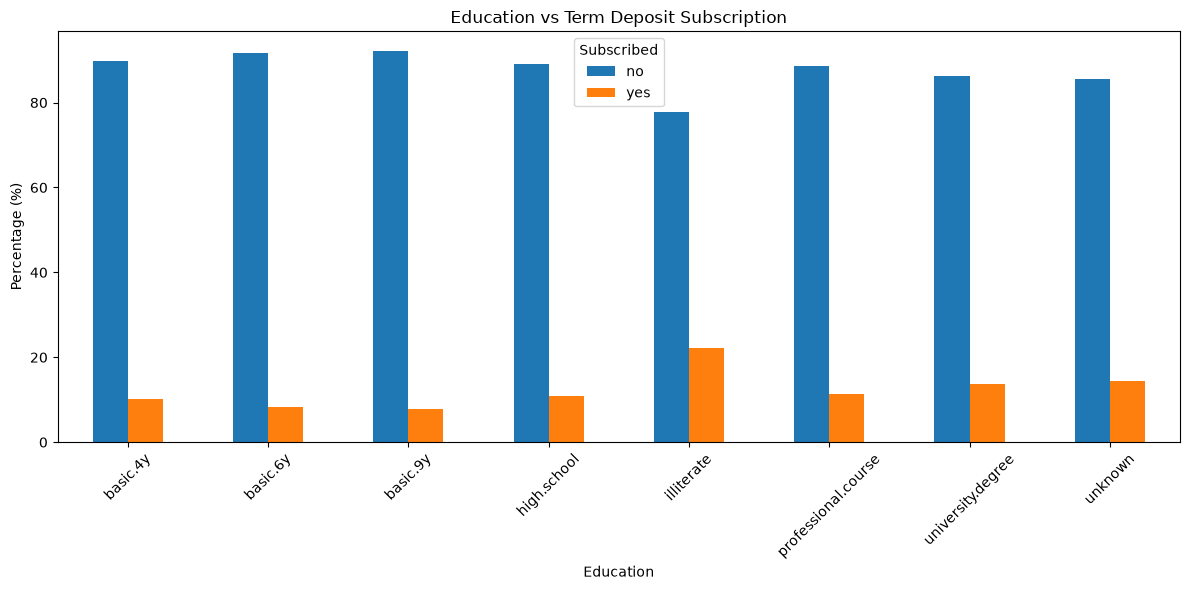

In [17]:
education_target = pd.crosstab(
    df['education'], df['y'], normalize='index'
) * 100

education_target.plot(kind='bar', figsize=(12, 6))
plt.title('Education vs Term Deposit Subscription')
plt.xlabel('Education')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

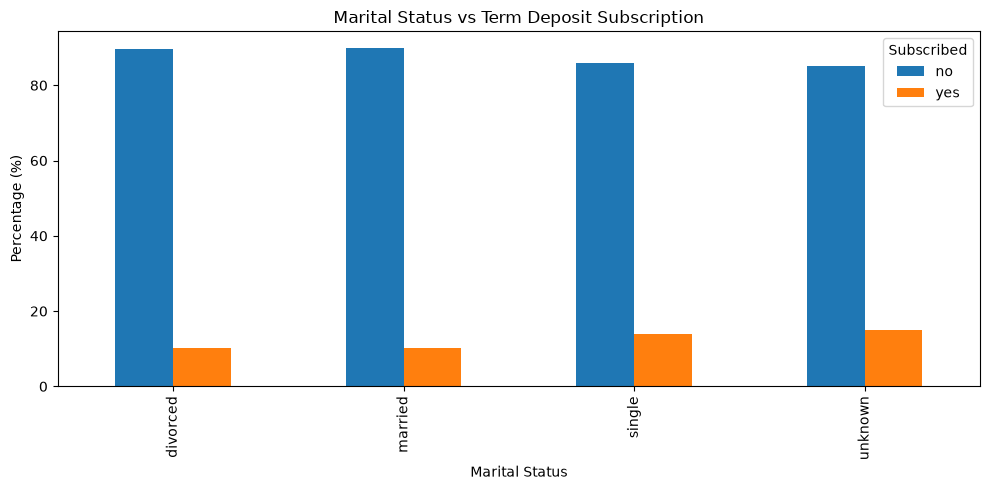

In [18]:
marital_target = pd.crosstab(
    df['marital'], df['y'], normalize='index'
) * 100

marital_target.plot(kind='bar', figsize=(10, 5))
plt.title('Marital Status vs Term Deposit Subscription')
plt.xlabel('Marital Status')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

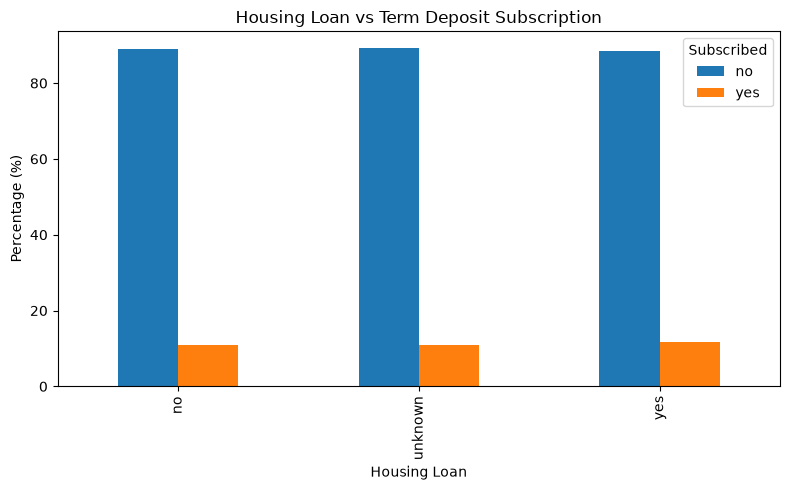

In [19]:
housing_target = pd.crosstab(
    df['housing'], df['y'], normalize='index'
) * 100

housing_target.plot(kind='bar', figsize=(8, 5))
plt.title('Housing Loan vs Term Deposit Subscription')
plt.xlabel('Housing Loan')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

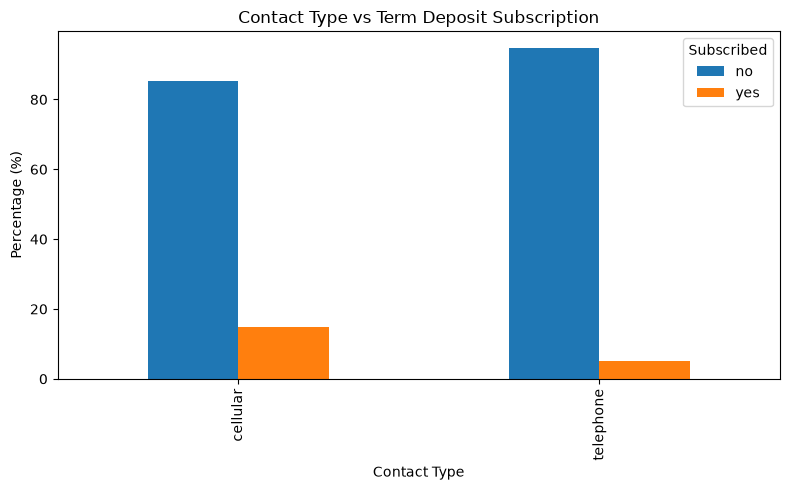

In [20]:
contact_target = pd.crosstab(
    df['contact'], df['y'], normalize='index'
) * 100

contact_target.plot(kind='bar', figsize=(8, 5))
plt.title('Contact Type vs Term Deposit Subscription')
plt.xlabel('Contact Type')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

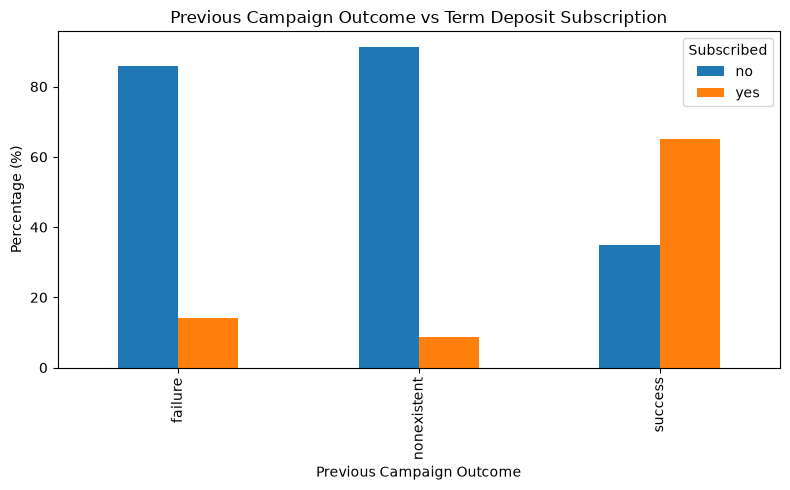

In [21]:
poutcome_target = pd.crosstab(
    df['poutcome'], df['y'], normalize='index'
) * 100

poutcome_target.plot(kind='bar', figsize=(8, 5))
plt.title('Previous Campaign Outcome vs Term Deposit Subscription')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

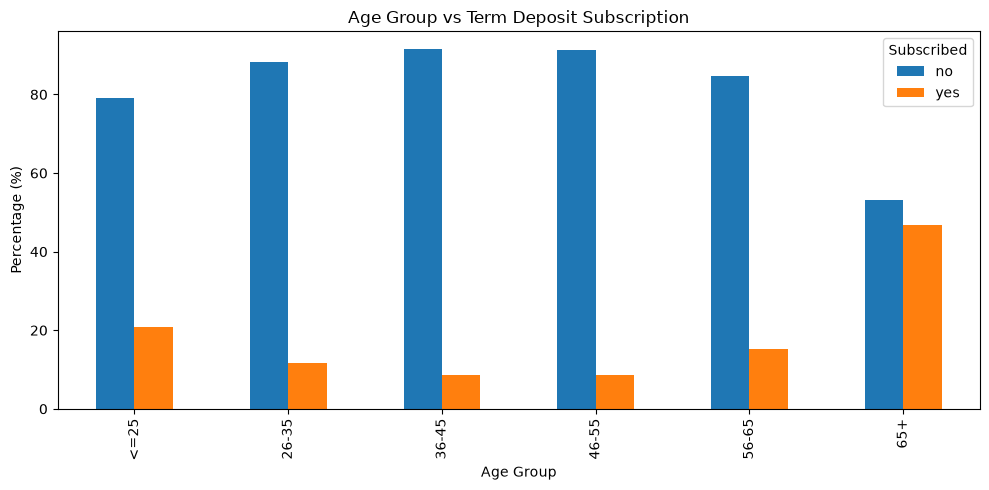

In [22]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<=25', '26-35', '36-45', '46-55', '56-65', '65+']
)

age_target = pd.crosstab(
    df['age_group'], df['y'], normalize='index'
) * 100

age_target.plot(kind='bar', figsize=(10, 5))
plt.title('Age Group vs Term Deposit Subscription')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

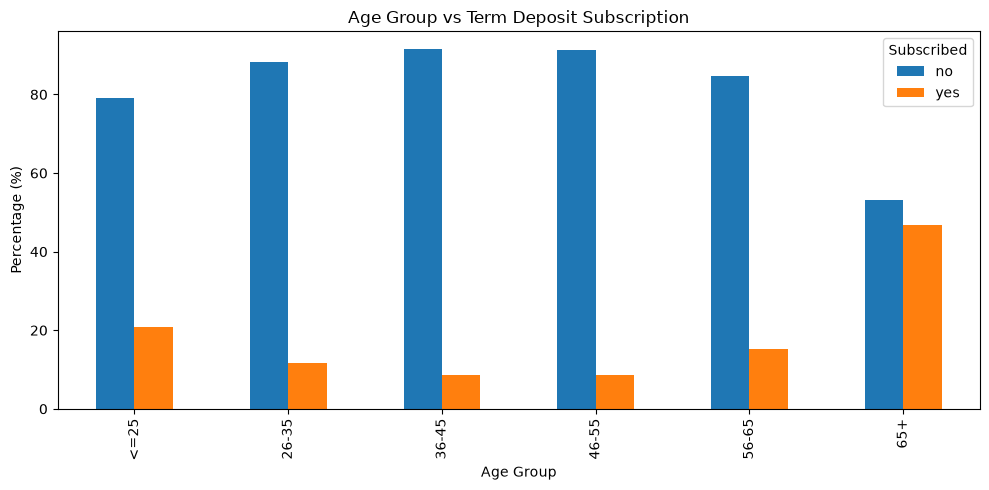

In [23]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<=25', '26-35', '36-45', '46-55', '56-65', '65+']
)

age_target = pd.crosstab(
    df['age_group'], df['y'], normalize='index'
) * 100

age_target.plot(kind='bar', figsize=(10, 5))
plt.title('Age Group vs Term Deposit Subscription')
plt.xlabel('Age Group')
plt.ylabel('Percentage (%)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

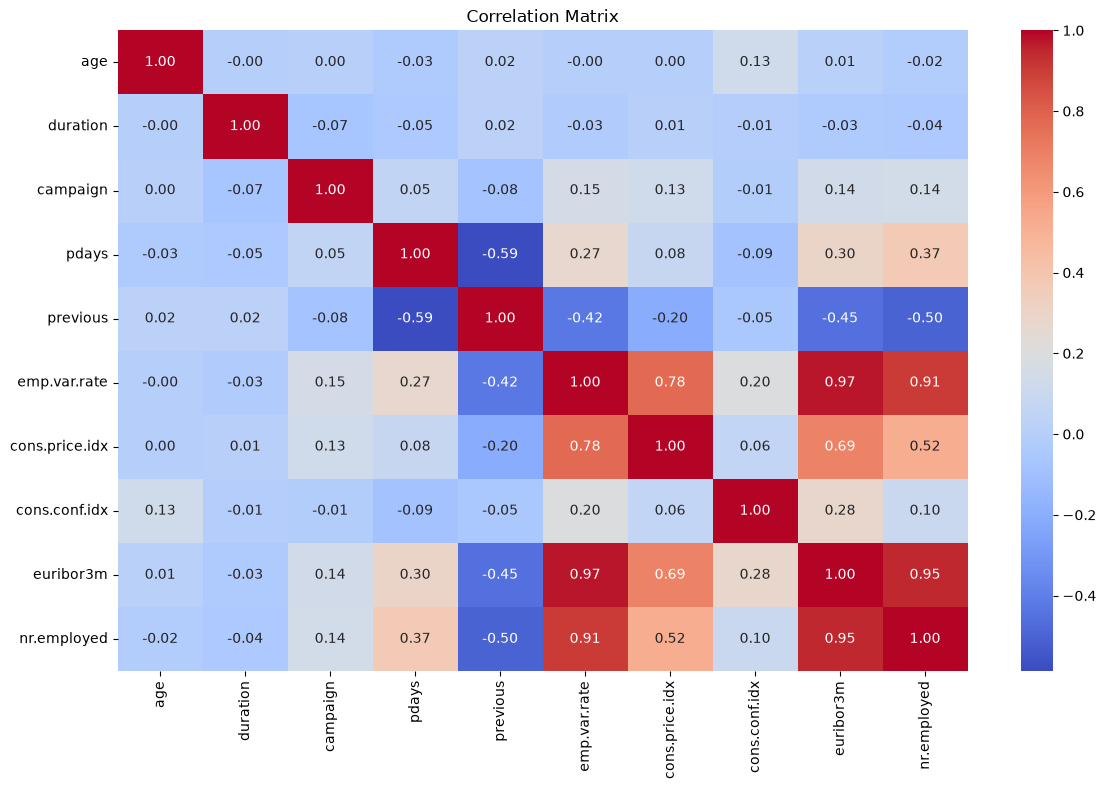

In [24]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

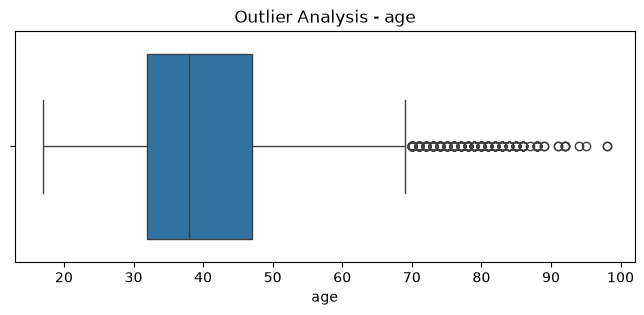

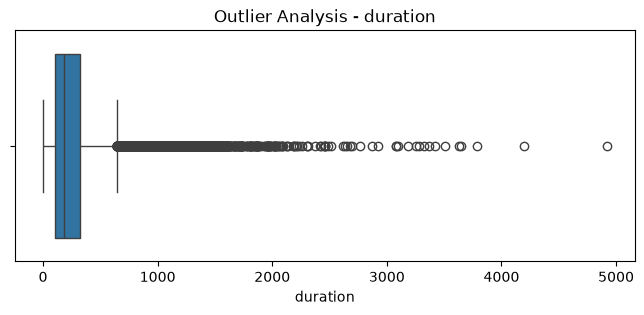

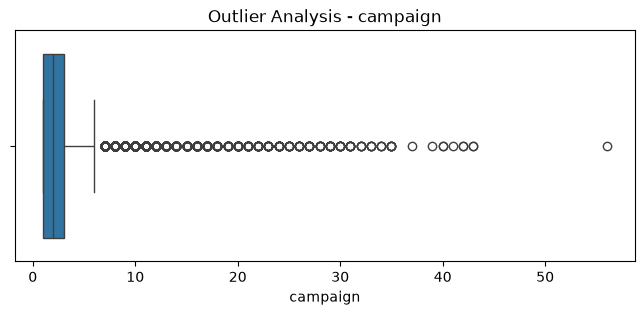

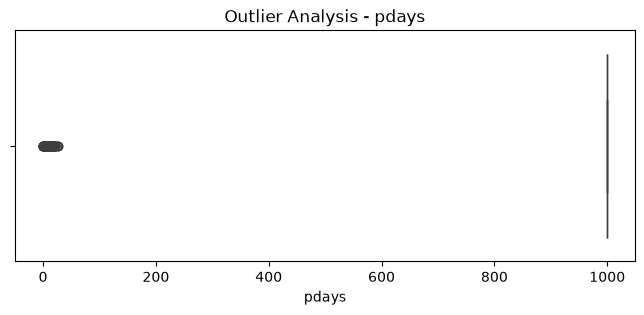

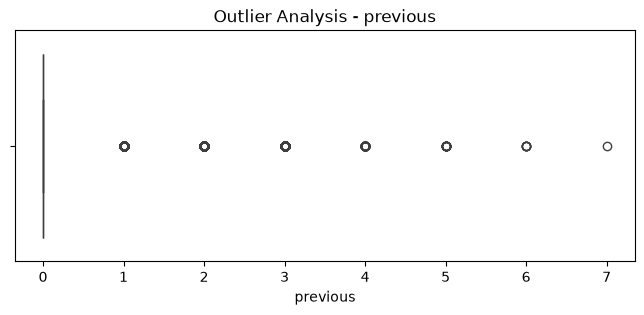

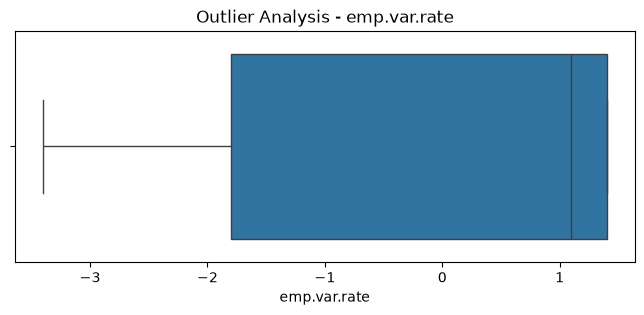

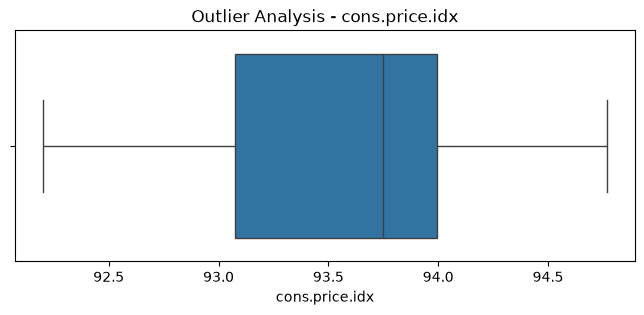

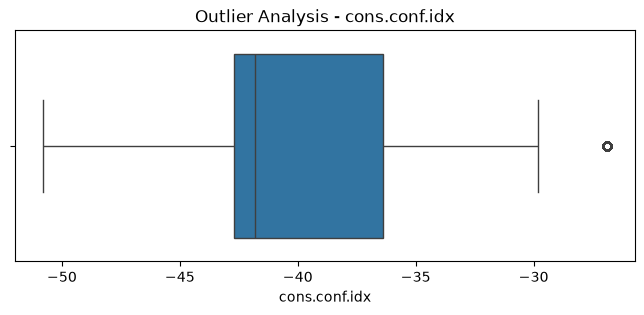

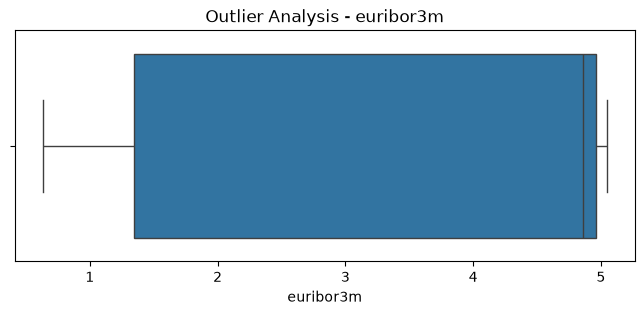

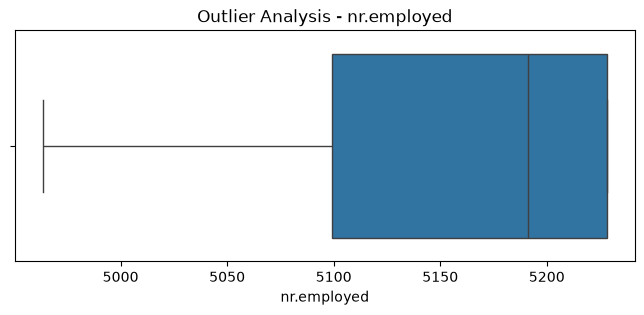

In [25]:
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Outlier Analysis - {col}')
    plt.show()

In [26]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"{col}: {len(outliers)} outliers")

age: 469 outliers
duration: 2963 outliers
campaign: 2406 outliers
pdays: 1515 outliers
previous: 5625 outliers
emp.var.rate: 0 outliers
cons.price.idx: 0 outliers
cons.conf.idx: 447 outliers
euribor3m: 0 outliers
nr.employed: 0 outliers


In [27]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,age_group
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,56-65
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,56-65
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,36-45
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,36-45
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,56-65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,65+
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,46-55
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,56-65
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,36-45


In [28]:
# dropped un wanted columns
df.drop(['duration','age_group'],axis=1,inplace=True)

In [29]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [30]:
# ------------------------
# Features and Target
# ------------------------

x=df.drop('y',axis=1)
y=df['y']

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (41188, 19)
Target shape: (41188,)


In [31]:
print(y.value_counts())
print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64

Target Percentage:
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


In [32]:
# ------------------------
# Train Test Split
# ------------------------


x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", x_train.shape)
print("Testing set :", x_test.shape)

Training set: (32950, 19)
Testing set : (8238, 19)


In [33]:
OHE_Columns = ['job','marital','education','default','housing','loan','contact','month','day_of_week','poutcome']

In [34]:
Scaling_Columns = ['age','campaign','pdays','previous','emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']

In [35]:
# One Hot Encoding Pipeline
ohe_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                     ('encoder', OneHotEncoder(handle_unknown='ignore'))])

# Scaling Pipeline
scale_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                       ('scaler', StandardScaler())])

# Column Transformer
preprocessor = ColumnTransformer([('ohe', ohe_pipe, OHE_Columns),   
                                  ('scaling', scale_pipe, Scaling_Columns)])

# Transform Data
x_train_tran = preprocessor.fit_transform(x_train)
x_test_tran = preprocessor.transform(x_test)

# Encode Target
# No = 0 , Yes = 1
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [36]:
print("Train Shape :", x_train_tran.shape)
print("Test Shape  :", x_test_tran.shape)

Train Shape : (32950, 62)
Test Shape  : (8238, 62)


In [37]:
# ------------------------
# Model Dictionary
# ------------------------

# Calculate class imbalance ratio for XGBoost
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_estimators=200,
        n_jobs=-1
    ),

    # Gradient Boosting does not directly support class_weight
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        scale_pos_weight=scale_pos_weight
    )
}


results = []

best_model_name = None
best_score = 0
best_model = None


print("\nTraining Started...\n")


# ------------------------
# Train Every Model
# ------------------------

for name, model in models.items():

    model.fit(x_train_tran, y_train)

    y_pred = model.predict(x_test_tran)

    y_prob = model.predict_proba(x_test_tran)[:, 1]

    # ------------------------
    # Evaluation Metrics
    # ------------------------

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test,y_pred,zero_division=0)

    recall = recall_score(y_test,y_pred,zero_division=0)

    f1 = f1_score(y_test,y_pred,zero_division=0)

    roc = roc_auc_score(y_test,y_prob)

    # Store results
    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc
    ])


    # ------------------------
    # Print Results
    # ------------------------

    print("=" * 60)
    print(name)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC AUC  : {roc:.4f}")


    # ------------------------
    # Select Best Model
    # ------------------------

    if roc > best_score:

        best_score = roc
        best_model_name = name
        best_model = model


# ------------------------
# Results Table
# ------------------------

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ]
)


print("\n")
print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

print(
    results_df
    .sort_values(by="ROC AUC", ascending=False)
    .to_string(index=True)
)


print("\nBest model based on ROC AUC:", best_model_name)

print("Best ROC AUC:", round(best_score, 4))

print("\nTraining Completed Successfully.")


Training Started...

Logistic Regression
Accuracy : 0.8350
Precision: 0.3679
Recall   : 0.6466
F1 Score : 0.4689
ROC AUC  : 0.8009
Decision Tree
Accuracy : 0.8477
Precision: 0.3255
Recall   : 0.3287
F1 Score : 0.3271
ROC AUC  : 0.6216
Random Forest
Accuracy : 0.8786
Precision: 0.4633
Recall   : 0.4892
F1 Score : 0.4759
ROC AUC  : 0.7869
Gradient Boosting
Accuracy : 0.9011
Precision: 0.6728
Recall   : 0.2371
F1 Score : 0.3506
ROC AUC  : 0.8092
XGBoost
Accuracy : 0.8454
Precision: 0.3831
Recall   : 0.6110
F1 Score : 0.4709
ROC AUC  : 0.7892


MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
3    Gradient Boosting  0.901068   0.672783  0.237069  0.350598  0.809161
0  Logistic Regression  0.835033   0.367872  0.646552  0.468933  0.800942
4              XGBoost  0.845351   0.383108  0.610991  0.470930  0.789224
2        Random Forest  0.878611   0.463265  0.489224  0.475891  0.786916
1        Decision Tree  0.847657   0.325507  0.328664  0.327078  

In [38]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model in models.items():
    
    y_pred = model.predict(x_test_tran)
    
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n{'='*60}")
    print(f"{name} - Classification Report")
    print(f"{'='*60}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['No', 'Yes']
    ))


Logistic Regression - Classification Report
              precision    recall  f1-score   support

          No       0.95      0.86      0.90      7310
         Yes       0.37      0.65      0.47       928

    accuracy                           0.84      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.84      0.85      8238


Decision Tree - Classification Report
              precision    recall  f1-score   support

          No       0.91      0.91      0.91      7310
         Yes       0.33      0.33      0.33       928

    accuracy                           0.85      8238
   macro avg       0.62      0.62      0.62      8238
weighted avg       0.85      0.85      0.85      8238


Random Forest - Classification Report
              precision    recall  f1-score   support

          No       0.93      0.93      0.93      7310
         Yes       0.46      0.49      0.48       928

    accuracy                           0.88      8238
   ma

#  hyperparameter tuning

In [39]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

In [40]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=2000
    ))
])

lr_params = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__solver': ['liblinear', 'lbfgs']
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(x_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_grid.best_params_)

print("Best CV ROC-AUC:")
print(lr_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression Parameters:
{'model__C': 0.1, 'model__solver': 'liblinear'}
Best CV ROC-AUC:
0.7901099874149191


In [41]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2],
    'model__max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(x_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best CV ROC-AUC:")
print(rf_grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Random Forest Parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV ROC-AUC:
0.7974171853904777


In [42]:
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        random_state=42
    ))
])

gb_params = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__max_depth': [2, 3, 5],
    'model__min_samples_split': [2, 5],
    'model__subsample': [0.8, 1.0]
}

gb_grid = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

gb_grid.fit(x_train, y_train)

print("Best Gradient Boosting Parameters:")
print(gb_grid.best_params_)

print("Best CV ROC-AUC:")
print(gb_grid.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Gradient Boosting Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best CV ROC-AUC:
0.7972271849413035


In [43]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_params = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(x_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

print("Best CV ROC-AUC:")
print(xgb_grid.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best XGBoost Parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best CV ROC-AUC:
0.7971042912505536


In [44]:
tuned_models = {
    'Logistic Regression': lr_grid.best_estimator_,
    'Random Forest': rf_grid.best_estimator_,
    'Gradient Boosting': gb_grid.best_estimator_,
    'XGBoost': xgb_grid.best_estimator_
}

In [ ]:
# --------------------------------
# Train Every Tuned Model
# --------------------------------

tuned_results = []

best_score = 0
best_model_name = None
best_model = None

for name, model in tuned_models.items():

    # Train pipeline using RAW DataFrame
    model.fit(x_train, y_train)

    # Predictions
    y_pred = model.predict(x_test)

    # Probability of positive class
    y_prob = model.predict_proba(x_test)[:, 1]

    # ------------------------
    # Evaluation Metrics
    # ------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc = roc_auc_score(
        y_test,
        y_prob
    )

    # Store results
    tuned_results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        roc
    ])

    # ------------------------
    # Print Results
    # ------------------------

    print("=" * 60)
    print(name)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC AUC  : {roc:.4f}")

    # ------------------------
    # Select Best Model
    # ------------------------

    if roc > best_score:
        best_score = roc
        best_model_name = name
        best_model = model


# --------------------------------
# Results Table
# --------------------------------

tuned_results_df = pd.DataFrame(
    tuned_results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ]
)

print("\n")
print("=" * 70)
print("TUNED MODEL COMPARISON")
print("=" * 70)

display(
    tuned_results_df
    .sort_values(
        by="ROC AUC",
        ascending=False
    )
    .round(4)
)

print("\nBest model based on ROC AUC:", best_model_name)
print("Best ROC AUC:", round(best_score, 4))

print("\nTraining Completed Successfully.")

Logistic Regression
Accuracy : 0.8337
Precision: 0.3657
Recall   : 0.6487
F1 Score : 0.4678
ROC AUC  : 0.8009
Random Forest
Accuracy : 0.8541
Precision: 0.4062
Recall   : 0.6390
F1 Score : 0.4966
ROC AUC  : 0.8147


In [50]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model in tuned_models.items():
    
    y_pred = model.predict(x_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n{'='*60}")
    print(f"{name} - Classification Report")
    print(f"{'='*60}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['No', 'Yes']
    ))


Logistic Regression - Classification Report
              precision    recall  f1-score   support

          No       0.95      0.86      0.90      7310
         Yes       0.37      0.65      0.47       928

    accuracy                           0.83      8238
   macro avg       0.66      0.75      0.68      8238
weighted avg       0.88      0.83      0.85      8238


Random Forest - Classification Report
              precision    recall  f1-score   support

          No       0.95      0.88      0.91      7310
         Yes       0.41      0.64      0.50       928

    accuracy                           0.85      8238
   macro avg       0.68      0.76      0.71      8238
weighted avg       0.89      0.85      0.87      8238


Gradient Boosting - Classification Report
              precision    recall  f1-score   support

          No       0.91      0.98      0.95      7310
         Yes       0.68      0.27      0.38       928

    accuracy                           0.90      8238
 

# Tuned Model Comparison Report

Four machine-learning models were hyperparameter-tuned and evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC. Five-fold stratified cross-validation was used during hyperparameter tuning to obtain reliable model performance.

Random Forest achieved the best overall performance, obtaining the highest ROC-AUC of 81.47% and the highest F1 Score of 49.66%. It also achieved 63.90% recall for the minority Yes class, making it a good balance between identifying potential customers and avoiding unnecessary marketing contacts.

Logistic Regression achieved a recall of 64.87%, showing good ability to identify customers who are likely to subscribe. However, its lower precision of 36.57% means that many predicted positive customers may not actually subscribe.

Gradient Boosting achieved the highest accuracy of 90.33% and highest precision of 67.85%. However, its recall was only 26.83%, meaning it missed a large proportion of customers who actually subscribed. Therefore, accuracy alone is not sufficient for selecting this model.

XGBoost achieved the highest recall of 65.84%, which is useful when the bank wants to identify as many potential subscribers as possible. However, its precision and F1 score were lower than Random Forest.

Recommended Model

Based on the overall evaluation, Random Forest is recommended as the production model because it achieved:

Highest ROC-AUC: 81.47%
Highest F1 Score: 49.66%
Good Recall: 63.90%
Better balance between Precision and Recall
Better overall performance than the other tuned models
  
For a banking marketing campaign, this balance is important because the objective is not simply to maximize accuracy, but to identify potential customers while reducing unnecessary marketing efforts.

# Report on Challenges faced

Unknown Values: Several categorical columns contained unknown values, with default having the highest proportion (20.87%). These were retained as a separate category to avoid data loss.

Class Imbalance: The target variable had significantly fewer yes cases than no cases. Class balancing was applied using class_weight='balanced' and scale_pos_weight for XGBoost.

Low Minority-Class Recall: Initial models showed high accuracy but low recall for the yes class. Class balancing was used to improve the identification of potential subscribers.

Data Leakage: The duration feature was removed because call duration is known only after the call and is not available before making a marketing decision. 

Multicollinearity: Strong correlations were found among economic variables such as emp.var.rate, euribor3m, and nr.employed, which may affect some models.

Categorical Data: Categorical variables could not be directly used by ML algorithms, so One-Hot Encoding was applied.

Hyperparameter Selection:Default model parameters may not provide the best performance for the dataset.
Hyperparameter tuning was performed using GridSearchCV with 5-fold Stratified Cross-Validation for the major candidate models. This helped select better model configurations while reducing the risk of relying on a single train-test split.

Model Selection: Different models produced different results across accuracy, precision, recall, F1-score, and ROC-AUC. Multiple evaluation metrics and hyperparameter tuning were considered before selecting Random Forest as the recommended model.

# Suggestions to the Bank Marketing Team

Target High-Potential Customers: Use the Random Forest model to identify customers who are more likely to subscribe to a term deposit and prioritize them for marketing campaigns.

Focus on Successful Customer Segments: Analyze customer characteristics such as age, job, education, contact type, previous campaign outcome, and economic factors to identify groups with higher subscription rates.

Optimize Contact Strategy: Use the model predictions to select the most suitable customers and avoid contacting customers unnecessarily, improving campaign efficiency.

Use Previous Campaign Results: Customers with successful outcomes from previous campaigns can be given higher priority for future marketing activities.

Personalize Marketing Offers: Design customer-specific offers based on demographic characteristics, previous interactions, and predicted subscription probability.

Prioritize Customers Using Prediction Scores: Rank customers according to their predicted probability of subscribing and focus marketing resources on higher-probability customers.

Avoid Excessive Contact: Monitor the number of contacts made to each customer and avoid repeated calls that may reduce campaign effectiveness.

Monitor Campaign Performance: Continuously track prediction performance and actual subscription results. Retrain or update the model when customer behavior or economic conditions change.

Make Data-Driven Decisions: Use the model along with business knowledge rather than relying only on traditional marketing strategies, helping the bank improve campaign efficiency and customer targeting.